In [1]:
import json

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit
from scipy.stats import gaussian_kde

# plt.rc("font", family="Nimbus Roman")
plt.rc("font", family="Nimbus Roman No9 L")

SMALL_SIZE = 7
MEDIUM_SIZE = 7
BIGGER_SIZE = 7

plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=SMALL_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=SMALL_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title

In [2]:
sim_lst = ["m12b", "m12c", "m12f", "m12i", "m12m"]
sim_dir = "/Users/z5114326/Documents/simulations/"

mw_gcs_fil = "../data/mw_gcs/mw_gcs.csv"
mw_gcs = pd.read_csv(mw_gcs_fil)

mw_gcs_cols_fil = "../data/mw_gcs/mw_gcs_colors_ref.csv"
mw_gcs_cols = pd.read_csv(mw_gcs_cols_fil)

mw_gc_class = "../data/mw_gcs/class_chen.txt"
mw_class = pd.read_csv(mw_gc_class, sep=r"\s+")

mw_class.loc[mw_class["Cluster"] == "ESO-SC06", "Cluster"] = "ESO_280-SC06"
mw_class.loc[mw_class["Cluster"] == "1636-283", "Cluster"] = "ESO_452-SC11"

mw_class = mw_class.rename(columns={"Cluster": "cluster_name"})

sim_fit_path = "../data/sim_data/boundary_fits.json"
with open(sim_fit_path, "r", encoding="utf-8") as f:
    sim_fit_dict = json.load(f)

sim_fit_upd_path = "../data/sim_data/boundary_fits_updated.json"
with open(sim_fit_upd_path, "r", encoding="utf-8") as f:
    sim_fit_upd_dict = json.load(f)

scmap = plt.get_cmap("tab10")
colors = [scmap(i) for i in np.linspace(0, 1, len(sim_lst))]
sim_colors = {sim: colors[i] for i, sim in enumerate(sim_lst)}

In [3]:
# $9.6^{+4.0}_{-2.6}

9.6 + 4 / (np.sum(mw_gcs["mass"]) * 1e-7)

10.674790593174778

In [4]:
np.sum(mw_gcs["mass"]) * 1e-7

3.7216552

In [5]:
def lower_bound(x, m, b):
    return m * x + b


def kde_threshold(Z, fraction):
    """Return KDE level that encloses fraction of total probability."""
    sorted_Z = np.sort(Z.ravel())[::-1]  # descending
    cumsum = np.cumsum(sorted_Z)
    cumsum /= cumsum[-1]  # normalize
    # Find the smallest Z value where cumulative sum >= fraction
    level = sorted_Z[np.searchsorted(cumsum, fraction)]
    return level


def get_lower_bound(
    x,
    y,
    xlims=(3.0, 8.0),
    ylims=(-1.0, 3.0),
    ngrid=500,
    cont_lvl=0.98,
):

    xlog = np.log10(x)
    ylog = np.log10(y)
    xylog = np.vstack([xlog, ylog])

    xmin, xmax = xlims
    ymin, ymax = ylims

    X, Y = np.meshgrid(
        np.linspace(xmin, xmax, ngrid),
        np.linspace(ymin, ymax, ngrid),
    )

    kde = gaussian_kde(xylog)
    Z = kde(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)

    lvl = kde_threshold(Z, cont_lvl)

    cont = plt.contour(X, Y, Z, levels=[lvl])
    plt.close()

    contp = cont.get_paths()[0]
    vert = contp.vertices

    xcon = vert[:, 0]
    ycon = vert[:, 1]

    xbins = np.linspace(xcon.min(), xcon.max(), 100)
    xbins_cen = 0.5 * (xbins[:-1] + xbins[1:])

    x_lower = []
    y_lower = []

    for i in range(len(xbins) - 1):
        mask = (xcon >= xbins[i]) & (xcon < xbins[i + 1])

        if np.any(mask):
            x_lower.append(xbins_cen[i])
            y_lower.append(np.min(ycon[mask]))

    x_lower = np.asarray(x_lower)
    y_lower = np.asarray(y_lower)

    p0 = [-1.0, 1.0]
    params, cov = curve_fit(lower_bound, x_lower, y_lower, p0=p0)

    best_fit_dict = {
        "m": params[0],
        "b": params[1],
        "cov": cov,
    }

    xfit = np.logspace(xmin, xmax)
    xfitlog = np.log10(xfit)

    yfitlog = lower_bound(xfitlog, *params)
    yfit = 10**yfitlog

    return xfit, yfit, best_fit_dict


def to_json_serializable(obj):
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    elif isinstance(obj, dict):
        return {k: to_json_serializable(v) for k, v in obj.items()}
    elif isinstance(obj, (list, tuple)):
        return [to_json_serializable(v) for v in obj]
    elif isinstance(obj, (np.integer, np.floating)):
        return obj.item()
    else:
        return obj

In [6]:
cont_lvl = 0.95
ngrid = 500

xmin, xmax = 3.0, 8.0
ymin, ymax = -1.0, 3.0
X, Y = np.meshgrid(np.linspace(xmin, xmax, ngrid), np.linspace(ymin, ymax, ngrid))

df_orb = mw_gcs.merge(
    mw_class[["cluster_name", "Origin"]],
    on="cluster_name",
    how="inner",
)

rsem = (df_orb["r_apo"] + df_orb["r_per"]) / 2
mini = 10 ** df_orb["log_mini"]
insitu = df_orb["Origin"] == "in-situ"

xi = mini[insitu]
yi = rsem[insitu]
xifit, yifit, fiti_dict = get_lower_bound(xi, yi)

xe = mini[~insitu]
ye = rsem[~insitu]
xefit, yefit, fite_dict = get_lower_bound(xe, ye)

bound_mw = {"in": fiti_dict, "ex": fite_dict}
bound_mw = to_json_serializable(bound_mw)

bound_mw_path = "../data/sim_data/boundary_mw_fits.json"
with open(bound_mw_path, "w", encoding="utf-8") as f:
    json.dump(bound_mw, f, indent=4)

In [7]:
mi_avg = np.round(fiti_dict["m"], 2)
mi_std = np.round(np.sqrt(fiti_dict["cov"][0, 0]), 2)
bi_avg = np.round(fiti_dict["b"], 2)
bi_std = np.round(np.sqrt(fiti_dict["cov"][1, 1]), 2)

print("MW in situ", "m:", mi_avg, "+/-", mi_std, "b:", bi_avg, "+/-", bi_std)

me_avg = np.round(fite_dict["m"], 2)
me_std = np.round(np.sqrt(fite_dict["cov"][0, 0]), 2)
be_avg = np.round(fite_dict["b"], 2)
be_std = np.round(np.sqrt(fite_dict["cov"][1, 1]), 2)

print("MW ex situ", "m:", me_avg, "+/-", me_std, "b:", be_avg, "+/-", be_std)

MW in situ m: -0.58 +/- 0.01 b: 3.46 +/- 0.06
MW ex situ m: -0.39 +/- 0.01 b: 2.77 +/- 0.06


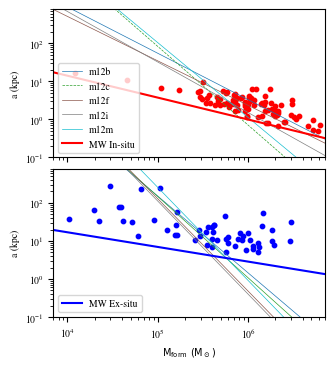

In [8]:
xmin, xmax = (3, 8)
xfitlog = np.linspace(xmin, xmax, 100)
xfit = 10**xfitlog

fig, axs = plt.subplots(2, 1, figsize=(3.5, 4.0))
plt.subplots_adjust(hspace=0.075)

# In-situ population ###########################################

for sim in sim_lst:
    if sim != "m12c":
        m = sim_fit_dict[sim]["in"]["m"]["50"]
        c = sim_fit_dict[sim]["in"]["c"]["50"]

        yfitlog = m * xfitlog + c
        yfit = 10**yfitlog

        axs[0].plot(xfit, yfit, c=sim_colors[sim], lw=0.5, label=sim)
    else:
        m = sim_fit_dict["m12c_5gyr_lim"]["in"]["m"]["50"]
        c = sim_fit_dict["m12c_5gyr_lim"]["in"]["c"]["50"]

        yfitlog = m * xfitlog + c
        yfit = 10**yfitlog

        axs[0].plot(xfit, yfit, c=sim_colors[sim], lw=0.5, ls="--", label="m12c")

axs[0].scatter(xi, yi, c="r", s=10)
axs[0].plot(xifit, yifit, c="r", label="MW In-situ")

axs[0].set_xscale("log")
axs[0].set_yscale("log")

axs[0].set_xlim(7 * 10**3, 7 * 10**6)
axs[0].set_ylim(10**-1, 8 * 10**2)

axs[0].set_xlabel("")
axs[0].set_xticklabels([])

axs[0].set_ylabel(r"a (kpc)")

axs[0].legend(loc="lower left")

# Ex-situ population ###########################################

for sim in sim_lst:
    m = sim_fit_dict[sim]["ex"]["m"]["50"]
    c = sim_fit_dict[sim]["ex"]["c"]["50"]

    yfitlog = m * xfitlog + c
    yfit = 10**yfitlog

    axs[1].plot(xfit, yfit, c=sim_colors[sim], lw=0.5)

axs[1].scatter(xe, ye, c="b", s=10)
axs[1].plot(xefit, yefit, c="b", label="MW Ex-situ")

axs[1].set_xscale("log")
axs[1].set_yscale("log")

axs[1].set_xlim(7 * 10**3, 7 * 10**6)
axs[1].set_ylim(10**-1, 8 * 10**2)

axs[1].set_xlabel(r"$\mathrm{M}_\mathrm{form}\ (\mathrm{M}_\odot)$")
axs[1].set_ylabel(r"a (kpc)")

axs[1].legend(loc="lower left")

mw_conts = "../data/figures/boundaries/mw_kde_boundaries.pdf"
fig.savefig(mw_conts)

# New Boundary Definition

In [9]:
# xmin, xmax = (3, 8)
# xfitlog = np.linspace(xmin, xmax, 100)
# xfit = 10**xfitlog

# fig, axs = plt.subplots(2, 1, figsize=(3.5, 4.0))
# plt.subplots_adjust(hspace=0.075)

# # In-situ population ###########################################

# for sim in sim_lst:
#     if sim != "m12c":
#         params = (sim_fit_upd_dict[sim]["in"]["avg"]["m"], sim_fit_upd_dict[sim]["in"]["avg"]["b"])

#         yfitlog = lower_bound(xfitlog, *params)
#         yfit = 10**yfitlog

#         axs[0].plot(xfit, yfit, c=sim_colors[sim], lw=1, label=sim)

#     else:
#         params = (
#             sim_fit_upd_dict["m12c_5gyr_lim"]["in"]["avg"]["m"],
#             sim_fit_upd_dict["m12c_5gyr_lim"]["in"]["avg"]["b"],
#         )

#         yfitlog = lower_bound(xfitlog, *params)
#         yfit = 10**yfitlog
#         axs[0].plot(xfit, yfit, c=sim_colors[sim], ls="--", lw=1, label="m12c")


# axs[0].scatter(xi, yi, c="r", s=10)
# axs[0].plot(xifit, yifit, c="r", label="Milky Way")

# axs[0].set_xscale("log")
# axs[0].set_yscale("log")

# axs[0].set_xlim(7 * 10**3, 7 * 10**6)
# axs[0].set_ylim(10**-1, 8 * 10**2)

# axs[0].set_xlabel("")
# axs[0].set_xticklabels([])

# axs[0].set_ylabel(r"a (kpc)")

# axs[0].legend(loc="lower left")

# # Ex-situ population ###########################################

# for sim in sim_lst:
#     params = (sim_fit_upd_dict[sim]["ex"]["avg"]["m"], sim_fit_upd_dict[sim]["ex"]["avg"]["b"])

#     yfitlog = lower_bound(xfitlog, *params)
#     yfit = 10**yfitlog

#     axs[1].plot(xfit, yfit, c=sim_colors[sim], lw=1)

# axs[1].scatter(xe, ye, c="b", s=10)
# axs[1].plot(xefit, yefit, c="b", label="Milky Way")

# axs[1].set_xscale("log")
# axs[1].set_yscale("log")

# axs[1].set_xlim(7 * 10**3, 7 * 10**6)
# axs[1].set_ylim(10**-1, 8 * 10**2)

# axs[1].set_xlabel(r"$\mathrm{M}_\mathrm{form}\ (\mathrm{M}_\odot)$")
# axs[1].set_ylabel(r"a (kpc)")

# axs[1].legend(loc="lower left")

# mw_conts = "../data/figures/boundaries/mw_kde_boundaries_updated.pdf"
# fig.savefig(mw_conts)

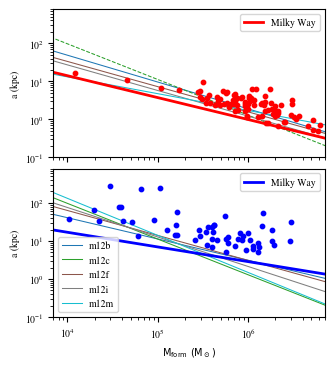

In [10]:
from matplotlib.lines import Line2D

xmin, xmax = (3, 8)
xfitlog = np.linspace(xmin, xmax, 100)
xfit = 10**xfitlog

fig, axs = plt.subplots(2, 1, figsize=(3.5, 4.0))
plt.subplots_adjust(hspace=0.075)

# In-situ population ###########################################

for sim in sim_lst:
    if sim != "m12c":
        params = (
            sim_fit_upd_dict[sim]["in"]["avg"]["m"],
            sim_fit_upd_dict[sim]["in"]["avg"]["b"],
        )

        yfitlog = lower_bound(xfitlog, *params)
        yfit = 10**yfitlog

        axs[0].plot(xfit, yfit, c=sim_colors[sim], lw=0.75, zorder=0)

    else:
        params = (
            sim_fit_upd_dict["m12c_5gyr_lim"]["in"]["avg"]["m"],
            sim_fit_upd_dict["m12c_5gyr_lim"]["in"]["avg"]["b"],
        )

        yfitlog = lower_bound(xfitlog, *params)
        yfit = 10**yfitlog

        axs[0].plot(xfit, yfit, c=sim_colors[sim], ls="--", lw=0.75, zorder=0)

axs[0].scatter(xi, yi, c="r", s=10)
axs[0].plot(xifit, yifit, c="r", lw=2)

axs[0].set_xscale("log")
axs[0].set_yscale("log")

axs[0].set_xlim(7 * 10**3, 7 * 10**6)
axs[0].set_ylim(10**-1, 8 * 10**2)

axs[0].set_xlabel("")
axs[0].set_xticklabels([])

axs[0].set_ylabel(r"a (kpc)")

# MW legend only (upper right)
axs[0].legend(
    handles=[
        Line2D([], [], color="r", lw=2, label="Milky Way"),
    ],
    loc="upper right",
)

# Ex-situ population ###########################################

for sim in sim_lst:
    params = (
        sim_fit_upd_dict[sim]["ex"]["avg"]["m"],
        sim_fit_upd_dict[sim]["ex"]["avg"]["b"],
    )

    yfitlog = lower_bound(xfitlog, *params)
    yfit = 10**yfitlog

    axs[1].plot(xfit, yfit, c=sim_colors[sim], lw=0.75, label=sim, zorder=0)

axs[1].scatter(xe, ye, c="b", s=10)
axs[1].plot(xefit, yefit, c="b", lw=2)

axs[1].set_xscale("log")
axs[1].set_yscale("log")

axs[1].set_xlim(7 * 10**3, 7 * 10**6)
axs[1].set_ylim(10**-1, 8 * 10**2)

axs[1].set_xlabel(r"$\mathrm{M}_\mathrm{form}\ (\mathrm{M}_\odot)$")
axs[1].set_ylabel(r"a (kpc)")

# Simulation legend (bottom left)
sim_legend = axs[1].legend(loc="lower left")

# MW legend (upper right)
mw_legend = axs[1].legend(
    handles=[
        Line2D([], [], color="b", lw=2, label="Milky Way"),
    ],
    loc="upper right",
)

axs[1].add_artist(sim_legend)

mw_conts = "../data/figures/boundaries/mw_kde_boundaries_updated.pdf"
fig.savefig(mw_conts)

# Implying MW mass loss:

In [11]:
def safe_interpolate(x, y, mass_grid):
    interp_func = interp1d(x, y, kind="linear", bounds_error=False, fill_value=(0, 1))
    return interp_func(mass_grid)


def get_cdf(arr):
    return np.cumsum(arr) / np.sum(arr)

In [12]:
mw_mform = 10 ** mw_gcs["log_mini"]
mw_mz0 = mw_gcs["mass"]

In [13]:
max_masss = 10 ** np.arange(4, 7.1, 0.1)
mass_dict = {sim: {"mass": []} for sim in sim_lst}

for sim in sim_lst:
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
    ghost_data = h5py.File(ghost_file, "r")

    # it_id = "it001"
    for it_id in ghost_data.keys():
        src_dat = ghost_data[it_id]["source"]

        mfors = 10 ** src_dat["logm_tfor"][()]
        mfor_evs = 0.55 * mfors
        mz0 = np.array([0 if m0 == -1 else 10**m0 for m0 in src_dat["logm_tz0"][()]])
        mdifs = mfor_evs - mz0

        # --- masks ---
        mass_arr = []
        for max_mass in max_masss:
            mmsk = mfors < max_mass

            mass = np.sum(mdifs[mmsk])
            mass_arr.append(mass)

        mass_arr = np.array(mass_arr)
        mass_dict[sim]["mass"].append(mass_arr)


smass_dict = {sim: {"mass": []} for sim in sim_lst}

for sim in sim_lst:
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
    ghost_data = h5py.File(ghost_file, "r")

    # it_id = "it001"
    for it_id in ghost_data.keys():
        src_dat = ghost_data[it_id]["source"]

        mfors = 10 ** src_dat["logm_tfor"][()]
        mfor_evs = 0.55 * mfors
        mz0 = np.array([0 if m0 == -1 else 10**m0 for m0 in src_dat["logm_tz0"][()]])

        # --- masks ---
        mass_arr = []
        for max_mass in max_masss:
            mmsk = mfors < max_mass

            mass = np.sum(mz0[mmsk])
            mass_arr.append(mass)

        mass_arr = np.array(mass_arr)
        smass_dict[sim]["mass"].append(mass_arr)


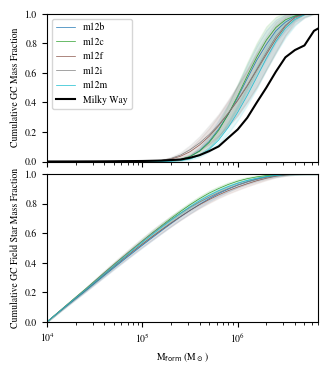

In [47]:
fig, axs = plt.subplots(2, 1, figsize=(3.5, 4.0))
plt.subplots_adjust(hspace=0.085)

ax = axs[0]
for sim in sim_lst:
    cdf_arr = []
    for mass_arr in smass_dict[sim]["mass"]:
        mass_total = mass_arr[-1]
        frac_cumulative = mass_arr / mass_total
        cdf_arr.append(frac_cumulative)

    cdf_avg = np.mean(cdf_arr, axis=0)
    cdf_std = np.std(cdf_arr, axis=0)

    ax.plot(max_masss, cdf_avg, c=sim_colors[sim], label=sim, lw=0.5)
    ax.fill_between(max_masss, cdf_avg + cdf_std, cdf_avg - cdf_std, color=sim_colors[sim], alpha=0.1)


mw_mass_sort = np.sort(np.asanyarray(mw_mform))
mw_mass_cdf = safe_interpolate(mw_mass_sort, get_cdf(mw_mass_sort), max_masss)
ax.plot(max_masss, mw_mass_cdf, c="k", label="Milky Way", lw=1.5)

ax.set_xscale("log")
ax.set_xlim(10**4, 7 * 10**6)
ax.set_xticklabels([])

ax.set_ylim(0, 1)
ax.set_ylabel(r"Cumulative GC Mass Fraction")

ax.legend(loc="upper left")

ax = axs[1]
for sim in sim_lst:
    cdf_arr = []
    for mass_arr in mass_dict[sim]["mass"]:
        mass_total = mass_arr[-1]
        frac_cumulative = mass_arr / mass_total
        cdf_arr.append(frac_cumulative)

    cdf_avg = np.mean(cdf_arr, axis=0)
    cdf_std = np.std(cdf_arr, axis=0)

    ax.plot(max_masss, cdf_avg, c=sim_colors[sim], label=sim, lw=0.5)
    ax.fill_between(max_masss, cdf_avg + cdf_std, cdf_avg - cdf_std, color=sim_colors[sim], alpha=0.1)


ax.set_xscale("log")
ax.set_xlim(10**4, 7 * 10**6)
ax.set_xlabel(r"M$_{\rm form}$ (M$_\odot$)")

ax.set_ylim(0, 1)
ax.set_ylabel(r"Cumulative GC Field Star Mass Fraction")

mw_cumul = "../data/figures/gc_plots/cumulative_mass_distributions.pdf"
fig.savefig(mw_cumul)


MW MASS NORMALISATION
MW surviving GC mass = 3.72e+07 Msun

Simulation calibration:
Mean/std      : 9.01 +/- 4.26
Median/68% CI : 8.27 [5.22, 12.71]

MW GC-origin field mass:
Preferred (percentiles): 3.08e+08 Msun
68% interval: [1.94e+08, 4.73e+08] Msun


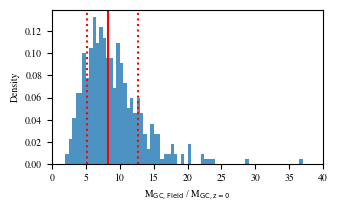

In [41]:
R_surv = []

for sim in sim_lst:
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"

    with h5py.File(ghost_file, "r") as ghost_data:
        for it_id in ghost_data.keys():
            src_dat = ghost_data[it_id]["source"]

            mz0 = np.array([0 if m == -1 else 10**m for m in src_dat["logm_tz0"][()]])

            Msurv = np.sum(mz0[mz0 > 0])

            idx = int(it_id.replace("it", "")) - 1

            if idx < len(mass_dict[sim]["mass"]):
                Mfield = mass_dict[sim]["mass"][idx][-1]

                if Msurv > 0:
                    R_surv.append(Mfield / Msurv)

R_surv = np.asarray(R_surv)

# ==========================================================
# SIMULATION CALIBRATION
# ==========================================================

Rmean = np.mean(R_surv)
Rstd = np.std(R_surv)

Rmed = np.median(R_surv)
R16 = np.percentile(R_surv, 16)
R84 = np.percentile(R_surv, 84)

# ==========================================================
# MILKY WAY
# ==========================================================

Msurv_MW = np.sum(mw_mz0)

Mfield_med = Rmed * Msurv_MW
Mfield_lo = R16 * Msurv_MW
Mfield_hi = R84 * Msurv_MW

# ==========================================================
# OUTPUT
# ==========================================================

print()
print("MW MASS NORMALISATION")
print("=================================================")

print(f"MW surviving GC mass = {Msurv_MW:.2e} Msun")

print()
print("Simulation calibration:")

print(f"Mean/std      : {Rmean:.2f} +/- {Rstd:.2f}")

print(f"Median/68% CI : {Rmed:.2f} [{R16:.2f}, {R84:.2f}]")

print()
print("MW GC-origin field mass:")

print(f"Preferred (percentiles): {Mfield_med:.2e} Msun")

print(f"68% interval: [{Mfield_lo:.2e}, {Mfield_hi:.2e}] Msun")

# ==========================================================
# PLOT
# ==========================================================

Rbins = np.arange(0, np.ceil(np.max(R_surv)) + 1, 0.5)

fig, ax = plt.subplots(1, 1, figsize=(3.5, 2.0))

ax.hist(R_surv, bins=Rbins, density=True, alpha=0.8)

ax.axvline(Rmed, c="r", lw=1.5)

ax.axvline(R16, c="r", ls=":", lw=1.5)

ax.axvline(R84, c="r", ls=":", lw=1.5)

ax.set_xlabel(r"M$_{\rm GC,Field}$ / M$_{\rm GC,z=0}$")
ax.set_ylabel("Density")

ax.set_xlim(0, 40)

mw_gc_field = "../data/figures/gc_plots/mass_field_ratios.pdf"
fig.savefig(mw_gc_field)


MW GC-FIELD MASS
Total field mass = 3.08e+08 Msun
68% interval = [1.94e+08, 4.73e+08] Msun


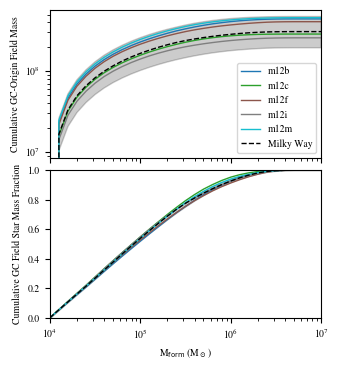

In [45]:
Ffield_sims = np.array([np.mean([m / m[-1] for m in mass_dict[sim]["mass"]], axis=0) for sim in sim_lst])

Ffield_sim = np.median(Ffield_sims, axis=0)
Ffield_sim_16 = np.percentile(Ffield_sims, 16, axis=0)
Ffield_sim_84 = np.percentile(Ffield_sims, 84, axis=0)

# ----------------------------------------------------------
# MW cumulative field mass
# ----------------------------------------------------------

Mfield_cum_MW = Mfield_med * Ffield_sim
Mfield_cum_lo = Mfield_lo * Ffield_sim_16
Mfield_cum_hi = Mfield_hi * Ffield_sim_84

# ----------------------------------------------------------
# BUILD PROPER LOG BIN EDGES
# ----------------------------------------------------------

logM = np.log10(max_masss)
dlog = np.median(np.diff(logM))
log_edges = np.concatenate([[logM[0] - dlog / 2], 0.5 * (logM[:-1] + logM[1:]), [logM[-1] + dlog / 2]])

M_edges = 10**log_edges

# ----------------------------------------------------------
# FIGURE
# ----------------------------------------------------------

fig, ax = plt.subplots(2, 1, figsize=(3.5, 4.0))
plt.subplots_adjust(hspace=0.085)

# ==========================================================
# LEFT PANEL
# CUMULATIVE FIELD MASS
# ==========================================================

for sim in sim_lst:
    Ffield = np.mean([m / m[-1] for m in mass_dict[sim]["mass"]], axis=0)
    # total field mass for this simulation
    Mfield_sim_tot = np.mean([m[-1] for m in mass_dict[sim]["mass"]])

    ax[0].plot(max_masss, Mfield_sim_tot * Ffield, alpha=1, lw=1, color=sim_colors[sim], label=sim)

ax[0].plot(max_masss, Mfield_cum_MW, c="k", lw=1, label="Milky Way", ls="--")
ax[0].fill_between(max_masss, Mfield_cum_lo, Mfield_cum_hi, color="k", alpha=0.2)

ax[0].set_xscale("log")
ax[0].set_yscale("log")

ax[0].set_xlim(1e4, 1e7)

ax[0].set_xticklabels([])

# ax[0].set_xlabel(r"$M_{\rm form}\,(M_\odot)$")
ax[0].set_ylabel(r"Cumulative GC-Origin Field Mass")

ax[0].legend(loc="lower right")


# ==========================================================
# RIGHT PANEL
# FIELD-STAR CDF
# ==========================================================

for sim in sim_lst:
    Ffield = np.mean([m / m[-1] for m in mass_dict[sim]["mass"]], axis=0)

    ax[1].plot(max_masss, Ffield, alpha=1, lw=1, color=sim_colors[sim])

ax[1].plot(max_masss, Ffield_sim, c="k", lw=1, label="Milky Way", ls="--")
ax[1].fill_between(max_masss, Ffield_sim_16, Ffield_sim_84, color="k", alpha=0.2)

ax[1].set_xscale("log")

ax[1].set_xlim(1e4, 1e7)
ax[1].set_ylim(0, 1)

ax[1].set_xlabel(r"M$_{\rm form}$ (M$_\odot$)")
ax[1].set_ylabel(r"Cumulative GC Field Star Mass Fraction")


# ----------------------------------------------------------
# NUMBERS
# ----------------------------------------------------------

print()
print("MW GC-FIELD MASS")
print("================================================")
print(f"Total field mass = {Mfield_med:.2e} Msun")
print(f"68% interval = [{Mfield_lo:.2e}, {Mfield_hi:.2e}] Msun")

mw_cumul = "../data/figures/gc_plots/cumulative_mass_field.pdf"
fig.savefig(mw_cumul)

25% of in-situ GC-origin field mass is associated with disruption inside a ≈ 2.11 kpc
50% of in-situ GC-origin field mass is associated with disruption inside a ≈ 4.16 kpc
75% of in-situ GC-origin field mass is associated with disruption inside a ≈ 7.67 kpc
90% of in-situ GC-origin field mass is associated with disruption inside a ≈ 11.11 kpc

25% of ex-situ GC-origin field mass is associated with disruption inside a ≈ 4.74 kpc
50% of ex-situ GC-origin field mass is associated with disruption inside a ≈ 7.46 kpc
75% of ex-situ GC-origin field mass is associated with disruption inside a ≈ 11.24 kpc
90% of ex-situ GC-origin field mass is associated with disruption inside a ≈ 14.41 kpc


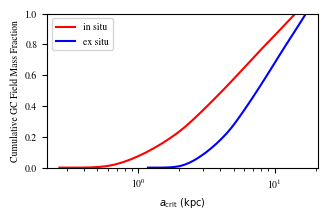

In [50]:
def radial_limits(xfit, yfit):

    # ----------------------------------------------------------
    # MW boundary relation
    # ----------------------------------------------------------

    a_of_M = interp1d(xfit, yfit, bounds_error=False, fill_value="extrapolate")

    acrit = a_of_M(max_masss)

    # ----------------------------------------------------------
    # Sort by radius
    # ----------------------------------------------------------

    order = np.argsort(acrit)

    a_sorted = acrit[order]
    F_sorted = Ffield_sim[order]

    # Cumulative field fraction interior to radius
    #
    # Since higher mass clusters correspond to smaller acrit,
    # we reverse before accumulating.
    # ----------------------------------------------------------

    F_radial = 1.0 - F_sorted

    return a_sorted, F_radial


as_i, Fr_i = radial_limits(xifit, yifit)
as_e, Fr_e = radial_limits(xefit, yefit)

# ----------------------------------------------------------
# Plot
# ----------------------------------------------------------

fig, ax = plt.subplots(1, 1, figsize=(3.5, 2.0))

ax.plot(as_i, Fr_i, c="r", lw=1.5, label="in situ")
ax.plot(as_e, Fr_e, c="b", lw=1.5, label="ex situ")

ax.set_xscale("log")

ax.set_xlabel(r"$a_{\rm crit}\ ({\rm kpc})$")

ax.set_ylabel(r"Cumulative GC Field Mass Fraction")

ax.set_ylim(0, 1)

ax.legend(loc="upper left")

# ----------------------------------------------------------
# Key radii
# ----------------------------------------------------------

for frac in [0.25, 0.5, 0.75, 0.9]:
    ari = np.interp(frac, Fr_i, as_i)
    it = f"{100 * frac:.0f}% of in-situ GC-origin field mass is associated with disruption inside a ≈ {ari:.2f} kpc"

    print(it)

print()

for frac in [0.25, 0.5, 0.75, 0.9]:
    are = np.interp(frac, Fr_e, as_e)
    et = f"{100 * frac:.0f}% of ex-situ GC-origin field mass is associated with disruption inside a ≈ {are:.2f} kpc"

    print(et)

mw_ml = "../data/figures/gc_plots/mw_mass_limits.pdf"
fig.savefig(mw_ml)